<a href="https://colab.research.google.com/github/cleberfmodesto/classificacao_xgboost/blob/main/Atividades/teste.ipynb" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-Colab-F9AB00?labelColor=F9AB00&logo=googlecolab&logoColor=white" alt="Abrir no Colab"/></a> <a href="https://github.com/cleberfmodesto/classificacao_xgboost/blob/main/Atividades/teste.ipynb" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-GitHub-0969DA?labelColor=0969DA&logo=github&logoColor=white" alt="Abrir GitHub"/></a> <a href="https://github.com/codespaces/new?repo=cleberfmodesto/classificacao_xgboost&ref=main" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-Codespaces-1F883D?labelColor=1F883D&logo=github&logoColor=white" alt="Abrir no Codespaces"/></a>

# 1. Importar os dados com Pandas

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/cleberfmodesto/regressao-xgboost-alura/main/Dados/insurance.csv"
dados = pd.read_csv(url)
dados.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# 2. Converter variáveis object para category

In [9]:
colunas_object = dados.select_dtypes(include="object").columns
dados[colunas_object] = dados[colunas_object].astype("category")

dados.dtypes

age            int64
sex         category
bmi          float64
children       int64
smoker      category
region      category
charges      float64
dtype: object

# 3. Criar X e y e separar treino e teste

In [10]:
from sklearn.model_selection import train_test_split

X = dados.drop(columns="charges")
y = dados["charges"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Importar o XGBoost

In [11]:
import xgboost as xgb

# 5. Criar as matrizes DMatrix

In [12]:
matriz_treino = xgb.DMatrix(
    X_treino, label=y_treino, enable_categorical=True
)
matriz_teste = xgb.DMatrix(
    X_teste, label=y_teste, enable_categorical=True
)

# 6. Treinar o modelo e realizar previsões

In [13]:
parametros = {
    "objective": "reg:squarederror",
    "eval_metric": "rmse",
    "tree_method": "hist",
    "seed": 42,
}

modelo = xgb.train(
    params=parametros,
    dtrain=matriz_treino,
    num_boost_round=200,
    evals=[(matriz_teste, "teste")],
    verbose_eval=False,
)

previsoes = modelo.predict(matriz_teste)

# 7. Calcular o RMSE

In [14]:
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(y_teste, previsoes) ** 0.5
print(f"RMSE: {rmse:.2f}")

RMSE: 4977.58


# 8. Validar o modelo com 5 dobras

A validação cruzada será aplicada ao conjunto de treino, mantendo o conjunto de teste reservado para a avaliação final.

 dobra  rmse_treino  rmse_validacao
     1       313.95         5822.85
     2       587.96         5762.13
     3       474.59         4777.18
     4       559.99         5681.93
     5       316.51         5575.81

RMSE médio de validação: 5523.98 (desvio-padrão: 427.61)


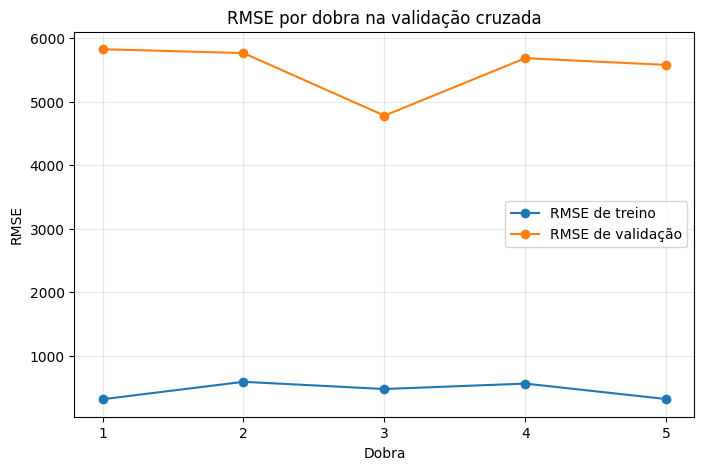

In [15]:
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
resultados = []

for numero_dobra, (indices_treino, indices_validacao) in enumerate(
    kfold.split(X_treino), start=1
):
    matriz_cv_treino = xgb.DMatrix(
        X_treino.iloc[indices_treino],
        label=y_treino.iloc[indices_treino],
        enable_categorical=True,
    )
    matriz_cv_validacao = xgb.DMatrix(
        X_treino.iloc[indices_validacao],
        label=y_treino.iloc[indices_validacao],
        enable_categorical=True,
    )

    modelo_cv = xgb.train(
        params=parametros,
        dtrain=matriz_cv_treino,
        num_boost_round=200,
        verbose_eval=False,
    )

    previsoes_treino = modelo_cv.predict(matriz_cv_treino)
    previsoes_validacao = modelo_cv.predict(matriz_cv_validacao)

    resultados.append(
        {
            "dobra": numero_dobra,
            "rmse_treino": mean_squared_error(
                y_treino.iloc[indices_treino], previsoes_treino
            ) ** 0.5,
            "rmse_validacao": mean_squared_error(
                y_treino.iloc[indices_validacao], previsoes_validacao
            ) ** 0.5,
        }
    )

resultados_cv = pd.DataFrame(resultados)
print(resultados_cv.round(2).to_string(index=False))
print(
    f"\nRMSE médio de validação: {resultados_cv['rmse_validacao'].mean():.2f} "
    f"(desvio-padrão: {resultados_cv['rmse_validacao'].std():.2f})"
)

plt.figure(figsize=(8, 5))
plt.plot(
    resultados_cv["dobra"],
    resultados_cv["rmse_treino"],
    marker="o",
    label="RMSE de treino",
)
plt.plot(
    resultados_cv["dobra"],
    resultados_cv["rmse_validacao"],
    marker="o",
    label="RMSE de validação",
)
plt.xticks(resultados_cv["dobra"])
plt.xlabel("Dobra")
plt.ylabel("RMSE")
plt.title("RMSE por dobra na validação cruzada")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Interpretação

O RMSE de treino ficou muito abaixo do RMSE de validação em todas as dobras, indicando possível overfitting. O RMSE médio de validação foi de aproximadamente **5.524**, com desvio-padrão de **428**. Uma próxima etapa seria comparar modelos com menos rodadas de boosting ou maior regularização, usando as mesmas dobras.

# 9. Validação cruzada com `xgb.cv`

A API nativa do XGBoost calcula as métricas médias e seus desvios-padrão nas 5 dobras para cada rodada. A validação usa a matriz de treino, preservando a matriz de teste para a avaliação final.

In [17]:
params_cv = parametros.copy()
params_cv["seed"] = 4789

cv_resultados = xgb.cv(
    dtrain=matriz_treino,
    params=params_cv,
    nfold=5,
    num_boost_round=1000,
    early_stopping_rounds=10,
    metrics="rmse",
    as_pandas=True,
    seed=4789,
    verbose_eval=False,
)

print(f"Rodadas executadas: {len(cv_resultados)}")
cv_resultados

Rodadas executadas: 10


,train-rmse-mean,train-rmse-std,test-rmse-mean,test-rmse-std
0,8951.364323,177.988235,9121.679599,772.353482
1,6911.228611,138.833159,7257.757092,621.631747
2,5571.956296,117.966664,6124.973219,510.423981
3,4705.094470,116.024461,5468.746812,468.353166
4,4152.142239,108.434856,5109.619777,420.324602
5,3780.902546,109.746814,4967.420051,406.062836
6,3529.823195,103.358285,4895.740268,384.074113
7,3349.993305,94.314138,4864.473741,364.120229
8,3220.351643,92.667195,4861.412815,359.149817
9,3095.309923,82.424635,4857.036652,358.429751


# 10. Visualizar o RMSE por rodada

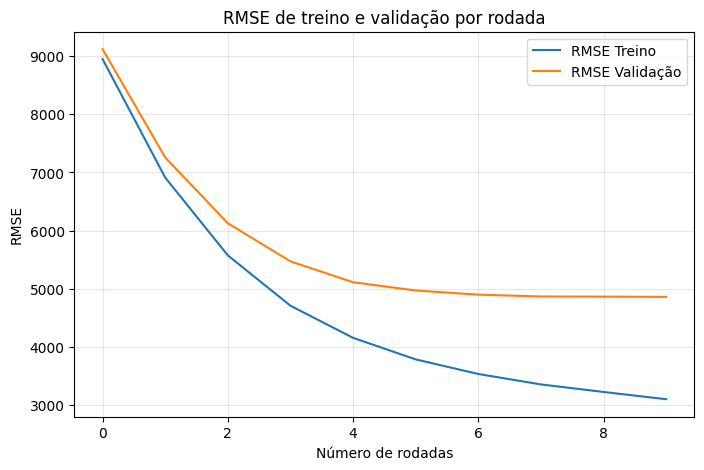

In [18]:
iteracoes = range(len(cv_resultados))

plt.figure(figsize=(8, 5))
plt.plot(
    iteracoes,
    cv_resultados["train-rmse-mean"],
    label="RMSE Treino",
)
plt.plot(
    iteracoes,
    cv_resultados["test-rmse-mean"],
    label="RMSE Validação",
)
plt.title("RMSE de treino e validação por rodada")
plt.xlabel("Número de rodadas")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 11. Ajustar hiperparâmetros com `GridSearchCV`

A busca usa validação cruzada de 5 dobras apenas nos dados de treino. O conjunto de teste permanece reservado para medir o desempenho final do melhor modelo.

In [19]:
from sklearn.model_selection import GridSearchCV
import numpy as np

param_grid = {
    "colsample_bytree": [0.6, 1],
    "subsample": [0.8, 1],
    "max_depth": [3, 5],
    "learning_rate": [0.1, 0.3],
}

gbm = xgb.XGBRegressor(
    enable_categorical=True,
    tree_method="hist",
    random_state=42,
    n_jobs=1,
)

grid = GridSearchCV(
    estimator=gbm,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=5,
    verbose=1,
)

grid.fit(X_treino, y_treino)

rmse_cv_min = np.sqrt(-grid.best_score_)
print("Melhores hiperparâmetros encontrados:", grid.best_params_)
print(f"Menor RMSE médio na validação cruzada: {rmse_cv_min:.2f}")

previsoes_grid = grid.best_estimator_.predict(X_teste)
rmse_teste_grid = mean_squared_error(y_teste, previsoes_grid) ** 0.5
print(f"RMSE no conjunto de teste reservado: {rmse_teste_grid:.2f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Melhores hiperparâmetros encontrados: {'colsample_bytree': 1, 'learning_rate': 0.1, 'max_depth': 3, 'subsample': 1}
Menor RMSE médio na validação cruzada: 4706.18
RMSE no conjunto de teste reservado: 4279.39


# 12. Validar os melhores parâmetros com `xgb.cv`

Esta etapa refaz a validação cruzada nativa do XGBoost usando os hiperparâmetros selecionados pelo GridSearchCV.

In [20]:
params_cv_otimizados = {
    "objective": "reg:squarederror",
    "colsample_bytree": 1,
    "max_depth": 3,
    "subsample": 1,
    "learning_rate": 0.1,
    "tree_method": "hist",
    "seed": 4789,
}

cv_resultados_otimizados = xgb.cv(
    dtrain=matriz_treino,
    params=params_cv_otimizados,
    nfold=5,
    num_boost_round=1000,
    early_stopping_rounds=10,
    metrics="rmse",
    as_pandas=True,
    seed=4789,
    verbose_eval=False,
)

print(f"Rodadas executadas: {len(cv_resultados_otimizados)}")
cv_resultados_otimizados

Rodadas executadas: 47


,train-rmse-mean,train-rmse-std,test-rmse-mean,test-rmse-std
0,11005.216105,215.141482,11043.928089,889.016133
1,10117.808941,195.720789,10168.152980,825.108952
2,9332.994057,179.006289,9401.307033,768.468190
3,8641.537912,164.567127,8718.557353,720.503294
4,8034.292623,151.869841,8117.322037,668.377666
5,7502.299203,140.921209,7594.767714,631.720503
6,7038.604716,131.890125,7134.655641,591.837656
7,6635.982921,123.762298,6745.056053,560.942113
8,6287.949409,117.543057,6407.914193,538.548803
9,5988.278392,112.068657,6113.666858,507.621846


# 13. Visualizar o RMSE com os melhores parâmetros

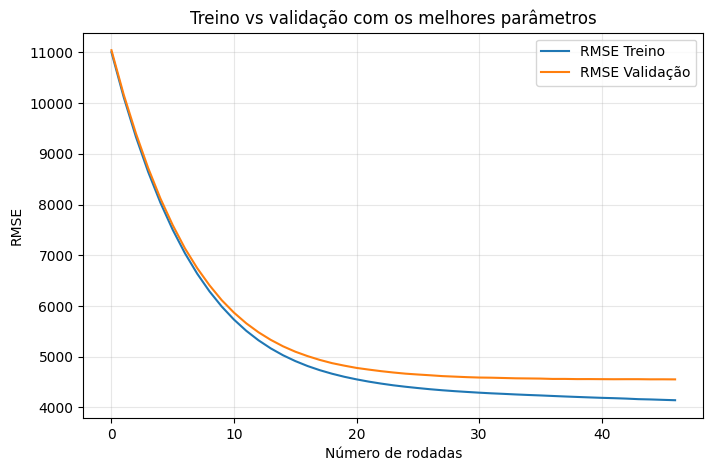

In [21]:
iteracoes_otimizadas = range(len(cv_resultados_otimizados))

plt.figure(figsize=(8, 5))
plt.plot(
    iteracoes_otimizadas,
    cv_resultados_otimizados["train-rmse-mean"],
    label="RMSE Treino",
)
plt.plot(
    iteracoes_otimizadas,
    cv_resultados_otimizados["test-rmse-mean"],
    label="RMSE Validação",
)
plt.title("Treino vs validação com os melhores parâmetros")
plt.xlabel("Número de rodadas")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()